# National University of Computer and Emerging Sciences
## Department of Computer Science
### Deep Learning for Perception — Assignment 1 (Fall 2026)



In [44]:
import os
import glob
import time
import copy
import random
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_diabetes
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    mean_squared_error,
    mean_absolute_error
)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, Dataset
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF


In [45]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Random seed:", SEED)
print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())


Random seed: 42
Device: cuda
CUDA available: True
GPU count: 2


## 0. Environment Setup & Data Preprocessing
* **Platform:** https://www.kaggle.com/
* **Accelerator:** GPU T4 x2 / CPU
* **Dataset:** Fashion-MNIST (Zalando Research)
* **Preprocessing:** Normalize pixel values to $[0, 1]$, and flatten each image into a $784$-dimensional vector ($28 	imes 28 	o 784$).
* **Splitting:** Split training data into an 80/20 train/validation split using stratification (`stratify=y_full`). Keep the test set untouched until Part 7.
* **Report:** Number of samples in each split and class distribution.


In [46]:
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Automatically locate the dataset files in Kaggle
INPUT_DIR = Path("/kaggle/input")

try:
    TRAIN_PATH = next(INPUT_DIR.rglob("fashion-mnist_train.csv"))
    TEST_PATH = next(INPUT_DIR.rglob("fashion-mnist_test.csv"))
    print(f"Detected Train Path: {TRAIN_PATH}")
    print(f"Detected Test Path:  {TEST_PATH}")
except StopIteration:
    # Fallback if running outside Kaggle locally
    TRAIN_PATH = Path("fashion-mnist_train.csv")
    TEST_PATH = Path("fashion-mnist_test.csv")
    print("Using local directory paths.")

# 2. Load data and process arrays
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

y_full = train_df.iloc[:, 0].to_numpy(dtype=np.int64)
X_full = train_df.iloc[:, 1:].to_numpy(dtype=np.float32) / 255.0
y_test = test_df.iloc[:, 0].to_numpy(dtype=np.int64)
X_test = test_df.iloc[:, 1:].to_numpy(dtype=np.float32) / 255.0

DATA_SOURCE = "Kaggle CSV"
print("Data source:", DATA_SOURCE)
print("Full training data shape:", X_full.shape)
print("Provided test data shape:", X_test.shape)
print("Pixel min/max:", X_full.min(), X_full.max())


Detected Train Path: /kaggle/input/datasets/f230552ehtishamul/dlp-assignment-1-dataset/fashion-mnist_train.csv
Detected Test Path:  /kaggle/input/datasets/f230552ehtishamul/dlp-assignment-1-dataset/fashion-mnist_test.csv
Data source: Kaggle CSV
Full training data shape: (60000, 784)
Provided test data shape: (10000, 784)
Pixel min/max: 0.0 1.0


## 1. Part 1: Backpropagation From Scratch (15 marks)
**Task:** Implement a two-layer MLP in NumPy only. No autograd and no deep learning framework.

* **Architecture:** $784$ to $64$ hidden units with ReLU activation, then $10$ output units with Softmax.
* **Loss Function:** Categorical Cross-Entropy:
  $$\mathcal{L} = -\frac{1}{N} \sum_{i=1}^N \sum_{k=1}^K y_{i,k} \log(\hat{y}_{i,k})$$
* **Requirements:**
  1. Implement forward pass, backward pass, and manual gradient descent update step.
  2. Train on a subset of 5000 samples for 20 epochs and plot the training loss curve.
  3. **Gradient Check:** Rebuild the same network in PyTorch, run one forward pass and one backward pass on the same batch ($N=128$) with the same initial weights, then print the maximum absolute difference between NumPy gradients and PyTorch autograd gradients for each weight matrix ($W_1, b_1, W_2, b_2$).
  4. State the maximum difference obtained and comment on whether implementation is correct.


In [47]:
X_train, X_val, y_train, y_val = train_test_split(
    X_full,
    y_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_full
)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))


Training samples: 48000
Validation samples: 12000
Test samples: 10000


In [48]:
def class_distribution(y):
    values, counts = np.unique(y, return_counts=True)
    return pd.DataFrame({
        "Class": values,
        "Count": counts,
        "Percentage": np.round(counts / len(y) * 100, 2)
    })
print("TRAINING DISTRIBUTION")
display(class_distribution(y_train))
print("VALIDATION DISTRIBUTION")
display(class_distribution(y_val))
print("TEST DISTRIBUTION")
display(class_distribution(y_test))


TRAINING DISTRIBUTION


,Class,Count,Percentage
0,0,4800,10.0
1,1,4800,10.0
2,2,4800,10.0
3,3,4800,10.0
4,4,4800,10.0
5,5,4800,10.0
6,6,4800,10.0
7,7,4800,10.0
8,8,4800,10.0
9,9,4800,10.0


VALIDATION DISTRIBUTION


,Class,Count,Percentage
0,0,1200,10.0
1,1,1200,10.0
2,2,1200,10.0
3,3,1200,10.0
4,4,1200,10.0
5,5,1200,10.0
6,6,1200,10.0
7,7,1200,10.0
8,8,1200,10.0
9,9,1200,10.0


TEST DISTRIBUTION


,Class,Count,Percentage
0,0,1000,10.0
1,1,1000,10.0
2,2,1000,10.0
3,3,1000,10.0
4,4,1000,10.0
5,5,1000,10.0
6,6,1000,10.0
7,7,1000,10.0
8,8,1000,10.0
9,9,1000,10.0


## 2. Part 2: Baseline Model and Activation Study (15 marks)
**Task:** Rebuild the network in PyTorch or Keras with at least two hidden layers ($784 	o 128 	o 64 	o 10$).

* **Experiments:**
  1. Train one version each with **Sigmoid**, **Tanh**, **ReLU**, and **LeakyReLU** ($\alpha=0.01$) in hidden layers. Keep everything else fixed.
  2. Plot all four validation loss curves on a single figure.
  3. Record the mean absolute gradient of the first hidden layer ($	ext{fc1}$) at Epoch 1 and at the final epoch for the Sigmoid model and the ReLU model.
  4. For the ReLU model, report the percentage of hidden units that output zero for every sample in a validation batch (Dead ReLU percentage).
* **Analytical Questions:**
  - Explain what your gradient numbers show about vanishing gradients (2 sentences).
  - Explain what the dead-unit percentage shows about ReLU (2 sentences).


In [49]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.long)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)
BATCH_SIZE = 128
def make_train_loader():
    return DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED)
    )
train_loader = make_train_loader()
val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=BATCH_SIZE,
    shuffle=False
)
print("Each flattened image has", X_train_t.shape[1], "features.")


Each flattened image has 784 features.


In [50]:
@torch.no_grad()
def evaluate_classifier(model, loader, criterion=None):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        logits = model(xb)
        if criterion is not None:
            loss = criterion(logits, yb)
            total_loss += loss.item() * xb.size(0)
        predictions = logits.argmax(dim=1)
        total_correct += (predictions == yb).sum().item()
        total_samples += xb.size(0)
    avg_loss = total_loss / total_samples if criterion is not None else np.nan
    accuracy = total_correct / total_samples
    return avg_loss, accuracy


In [51]:
def train_torch_classifier(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    epochs=20,
    record_first_layer_gradient=False
):
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "first_layer_grad": []
    }
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_samples = 0
        epoch_gradients = []
        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            if record_first_layer_gradient:
                grad = model.fc1.weight.grad
                epoch_gradients.append(grad.abs().mean().item())
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            running_correct += (logits.argmax(dim=1) == yb).sum().item()
            running_samples += xb.size(0)
        train_loss = running_loss / running_samples
        train_acc = running_correct / running_samples
        val_loss, val_acc = evaluate_classifier(
            model,
            val_loader,
            criterion
        )
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if record_first_layer_gradient:
            history["first_layer_grad"].append(np.mean(epoch_gradients))
        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )
    return history


### Part 1 Execution & Gradient Verification


In [52]:
part1_indices, _ = train_test_split(
    np.arange(len(X_train)),
    train_size=5000,
    random_state=SEED,
    stratify=y_train
)
X_part1 = X_train[part1_indices]
y_part1 = y_train[part1_indices]
print("Part 1 subset shape:", X_part1.shape)
print("Part 1 target shape:", y_part1.shape)


Part 1 subset shape: (5000, 784)
Part 1 target shape: (5000,)


In [53]:
rng = np.random.default_rng(SEED)
W1 = rng.normal(0, np.sqrt(2 / 784), size=(784, 64)).astype(np.float64)
b1 = np.zeros((1, 64), dtype=np.float64)
W2 = rng.normal(0, np.sqrt(2 / 64), size=(64, 10)).astype(np.float64)
b2 = np.zeros((1, 10), dtype=np.float64)
W1_check = W1.copy()
b1_check = b1.copy()
W2_check = W2.copy()
b2_check = b2.copy()
print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)


W1: (784, 64)
b1: (1, 64)
W2: (64, 10)
b2: (1, 10)


In [54]:
def relu_np(z):
    return np.maximum(0, z)
def softmax_np(z):
    z_shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)
def forward_np(X, W1, b1, W2, b2):
    z1 = X @ W1 + b1
    a1 = relu_np(z1)

    z2 = a1 @ W2 + b2
    probs = softmax_np(z2)

    cache = (X, z1, a1, z2, probs)
    return probs, cache


In [55]:
def cross_entropy_np(probs, y):
    eps = 1e-12
    correct_probabilities = probs[np.arange(len(y)), y]
    return -np.mean(np.log(correct_probabilities + eps))
def backward_np(cache, y, W2):
    X, z1, a1, z2, probs = cache
    n = X.shape[0]
    dz2 = probs.copy()
    dz2[np.arange(n), y] -= 1
    dz2 /= n
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)
    da1 = dz2 @ W2.T
    dz1 = da1 * (z1 > 0)
    dW1 = X.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)
    return dW1, db1, dW2, db2


In [56]:
gradient_batch_X = X_part1[:128].astype(np.float64)
gradient_batch_y = y_part1[:128]
np_probs, np_cache = forward_np(
    gradient_batch_X,
    W1_check,
    b1_check,
    W2_check,
    b2_check
)
np_dW1, np_db1, np_dW2, np_db2 = backward_np(
    np_cache,
    gradient_batch_y,
    W2_check
)
torch_gradient_model = nn.Sequential(
    nn.Linear(784, 64, dtype=torch.float64),
    nn.ReLU(),
    nn.Linear(64, 10, dtype=torch.float64)
)
with torch.no_grad():
    torch_gradient_model[0].weight.copy_(
        torch.tensor(W1_check.T, dtype=torch.float64)
    )
    torch_gradient_model[0].bias.copy_(
        torch.tensor(b1_check.ravel(), dtype=torch.float64)
    )
    torch_gradient_model[2].weight.copy_(
        torch.tensor(W2_check.T, dtype=torch.float64)
    )
    torch_gradient_model[2].bias.copy_(
        torch.tensor(b2_check.ravel(), dtype=torch.float64)
    )
x_t = torch.tensor(
    gradient_batch_X,
    dtype=torch.float64
)
y_t = torch.tensor(
    gradient_batch_y,
    dtype=torch.long
)
criterion_check = nn.CrossEntropyLoss()
logits_t = torch_gradient_model(x_t)
loss_t = criterion_check(
    logits_t,
    y_t
)
loss_t.backward()
torch_dW1 = (
    torch_gradient_model[0]
    .weight
    .grad
    .detach()
    .numpy()
    .T
)
torch_db1 = (
    torch_gradient_model[0]
    .bias
    .grad
    .detach()
    .numpy()
    .reshape(1, -1)
)
torch_dW2 = (
    torch_gradient_model[2]
    .weight
    .grad
    .detach()
    .numpy()
    .T
)
torch_db2 = (
    torch_gradient_model[2]
    .bias
    .grad
    .detach()
    .numpy()
    .reshape(1, -1)
)
diff_W1 = np.max(
    np.abs(np_dW1 - torch_dW1)
)
diff_b1 = np.max(
    np.abs(np_db1 - torch_db1)
)
diff_W2 = np.max(
    np.abs(np_dW2 - torch_dW2)
)
diff_b2 = np.max(
    np.abs(np_db2 - torch_db2)
)
overall_max_difference = max(
    diff_W1,
    diff_b1,
    diff_W2,
    diff_b2
)
print("Maximum absolute gradient differences")
print(f"W1: {diff_W1:.12e}")
print(f"b1: {diff_b1:.12e}")
print(f"W2: {diff_W2:.12e}")
print(f"b2: {diff_b2:.12e}")
print(
    "\nOverall maximum absolute difference:",
    f"{overall_max_difference:.12e}"
)
if overall_max_difference < 1e-8:
    print(
        "\nGradient check result: PASS"
    )
    print(
        "The NumPy gradients and PyTorch gradients "
        "agree very closely."
    )
else:
    print(
        "\nGradient check result: CHECK IMPLEMENTATION"
    )
    print(
        "The gradient difference is larger than expected."
    )


Maximum absolute gradient differences
W1: 2.775557561563e-17
b1: 4.163336342344e-17
W2: 5.551115123126e-17
b2: 4.163336342344e-17

Overall maximum absolute difference: 5.551115123126e-17

Gradient check result: PASS
The NumPy gradients and PyTorch gradients agree very closely.


In [57]:
PART1_EPOCHS = 20
PART1_BATCH_SIZE = 128
PART1_LR = 0.05
part1_losses = []
for epoch in range(PART1_EPOCHS):
    permutation = np.random.default_rng(SEED + epoch).permutation(len(X_part1))
    epoch_loss = 0.0
    seen = 0
    for start in range(0, len(X_part1), PART1_BATCH_SIZE):
        batch_idx = permutation[start:start + PART1_BATCH_SIZE]
        xb = X_part1[batch_idx].astype(np.float64)
        yb = y_part1[batch_idx]
        probs, cache = forward_np(xb, W1, b1, W2, b2)
        loss = cross_entropy_np(probs, yb)
        dW1, db1, dW2, db2 = backward_np(cache, yb, W2)
        W1 -= PART1_LR * dW1
        b1 -= PART1_LR * db1
        W2 -= PART1_LR * dW2
        b2 -= PART1_LR * db2
        epoch_loss += loss * len(xb)
        seen += len(xb)
    mean_epoch_loss = epoch_loss / seen
    part1_losses.append(mean_epoch_loss)
    print(f"Epoch {epoch + 1:02d}/{PART1_EPOCHS} - Loss: {mean_epoch_loss:.4f}")


Epoch 01/20 - Loss: 1.4739
Epoch 02/20 - Loss: 0.9533
Epoch 03/20 - Loss: 0.8346
Epoch 04/20 - Loss: 0.7512
Epoch 05/20 - Loss: 0.7314
Epoch 06/20 - Loss: 0.6400
Epoch 07/20 - Loss: 0.6264
Epoch 08/20 - Loss: 0.6009
Epoch 09/20 - Loss: 0.5857
Epoch 10/20 - Loss: 0.5541
Epoch 11/20 - Loss: 0.5465
Epoch 12/20 - Loss: 0.5396
Epoch 13/20 - Loss: 0.5552
Epoch 14/20 - Loss: 0.5418
Epoch 15/20 - Loss: 0.5041
Epoch 16/20 - Loss: 0.5123
Epoch 17/20 - Loss: 0.4945
Epoch 18/20 - Loss: 0.4941
Epoch 19/20 - Loss: 0.4821
Epoch 20/20 - Loss: 0.4745


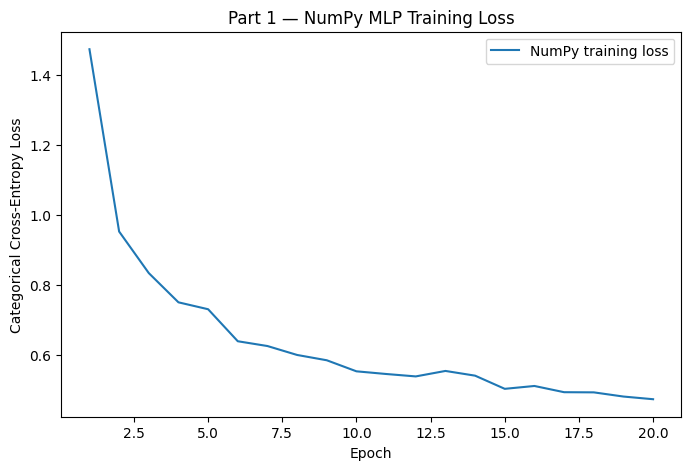

In [58]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, PART1_EPOCHS + 1),
    part1_losses,
    label="NumPy training loss"
)
plt.xlabel("Epoch")
plt.ylabel("Categorical Cross-Entropy Loss")
plt.title("Part 1 — NumPy MLP Training Loss")
plt.legend()
plt.show()


### Part 2 Activation Experiment Execution


In [59]:
class ActivationMLP(nn.Module):
    def __init__(self, activation_name):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)
        if activation_name == "sigmoid":
            self.act1 = nn.Sigmoid()
            self.act2 = nn.Sigmoid()
        elif activation_name == "tanh":
            self.act1 = nn.Tanh()
            self.act2 = nn.Tanh()
        elif activation_name == "relu":
            self.act1 = nn.ReLU()
            self.act2 = nn.ReLU()
        elif activation_name == "leaky_relu":
            self.act1 = nn.LeakyReLU(negative_slope=0.01)
            self.act2 = nn.LeakyReLU(negative_slope=0.01)
        else:
            raise ValueError("Unknown activation")
    def forward(self, x):
        x = self.act1(self.fc1(x))
        x = self.act2(self.fc2(x))
        return self.fc3(x)


In [60]:
ACTIVATIONS = ["sigmoid", "tanh", "relu", "leaky_relu"]
PART2_EPOCHS = 20
PART2_LR = 0.05
part2_histories = {}
part2_models = {}
for activation_name in ACTIVATIONS:
    print("\n" + "=" * 70)
    print("Activation:", activation_name)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)
    model = ActivationMLP(activation_name).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=PART2_LR
    )
    current_train_loader = make_train_loader()
    history = train_torch_classifier(
        model,
        current_train_loader,
        val_loader,
        optimizer,
        criterion,
        epochs=PART2_EPOCHS,
        record_first_layer_gradient=(
            activation_name in ["sigmoid", "relu"]
        )
    )
    part2_histories[activation_name] = history
    part2_models[activation_name] = copy.deepcopy(
        model.state_dict()
    )



Activation: sigmoid
Epoch 01/20 | Train Loss: 2.2900 | Train Acc: 0.1436 | Val Loss: 2.2631 | Val Acc: 0.1016
Epoch 02/20 | Train Loss: 2.1305 | Train Acc: 0.3193 | Val Loss: 1.8620 | Val Acc: 0.3536
Epoch 03/20 | Train Loss: 1.6075 | Train Acc: 0.4773 | Val Loss: 1.3990 | Val Acc: 0.5282
Epoch 04/20 | Train Loss: 1.2738 | Train Acc: 0.5735 | Val Loss: 1.1707 | Val Acc: 0.6038
Epoch 05/20 | Train Loss: 1.1045 | Train Acc: 0.6096 | Val Loss: 1.0439 | Val Acc: 0.6194
Epoch 06/20 | Train Loss: 0.9988 | Train Acc: 0.6352 | Val Loss: 0.9524 | Val Acc: 0.6443
Epoch 07/20 | Train Loss: 0.9183 | Train Acc: 0.6581 | Val Loss: 0.8816 | Val Acc: 0.6681
Epoch 08/20 | Train Loss: 0.8523 | Train Acc: 0.6833 | Val Loss: 0.8216 | Val Acc: 0.6854
Epoch 09/20 | Train Loss: 0.7952 | Train Acc: 0.7081 | Val Loss: 0.7684 | Val Acc: 0.7230
Epoch 10/20 | Train Loss: 0.7458 | Train Acc: 0.7285 | Val Loss: 0.7237 | Val Acc: 0.7291
Epoch 11/20 | Train Loss: 0.7044 | Train Acc: 0.7408 | Val Loss: 0.6890 | Val A

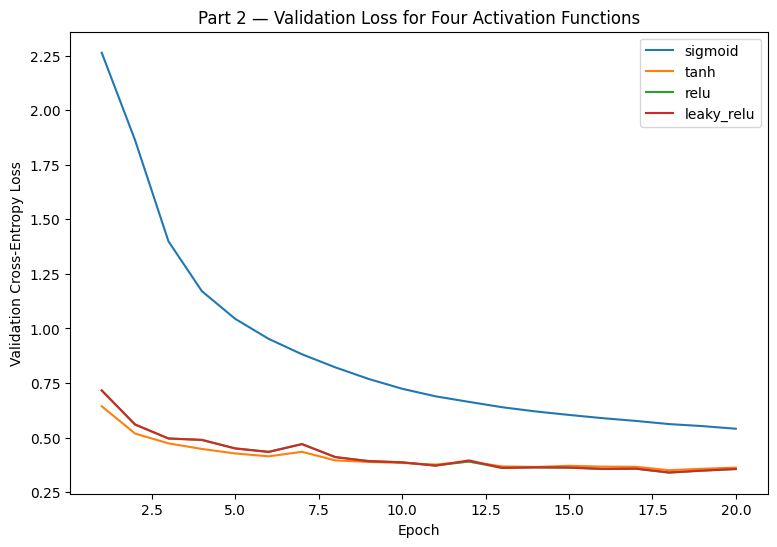

In [61]:
plt.figure(figsize=(9, 6))
for activation_name in ACTIVATIONS:
    plt.plot(
        range(1, PART2_EPOCHS + 1),
        part2_histories[activation_name]["val_loss"],
        label=activation_name
    )
plt.xlabel("Epoch")
plt.ylabel("Validation Cross-Entropy Loss")
plt.title("Part 2 — Validation Loss for Four Activation Functions")
plt.legend()
plt.show()


In [62]:
for activation_name in ["sigmoid", "relu"]:
    gradients = part2_histories[
        activation_name
    ]["first_layer_grad"]
    epoch1_gradient = gradients[0]
    final_gradient = gradients[-1]
    print("=" * 60)
    print(f"Activation: {activation_name.upper()}")
    print(
        f"Mean absolute first-layer gradient at epoch 1: "
        f"{epoch1_gradient:.10f}"
    )
    print(
        f"Mean absolute first-layer gradient at final epoch: "
        f"{final_gradient:.10f}"
    )
print("=" * 60)


Activation: SIGMOID
Mean absolute first-layer gradient at epoch 1: 0.0000984376
Mean absolute first-layer gradient at final epoch: 0.0005451871
Activation: RELU
Mean absolute first-layer gradient at epoch 1: 0.0012686272
Mean absolute first-layer gradient at final epoch: 0.0022450272


In [63]:
relu_model = ActivationMLP("relu").to(DEVICE)
relu_model.load_state_dict(part2_models["relu"])
relu_model.eval()
xb, yb = next(iter(val_loader))
xb = xb.to(DEVICE)
with torch.no_grad():
    h1 = relu_model.act1(
        relu_model.fc1(xb)
    )
    h2 = relu_model.act2(
        relu_model.fc2(h1)
    )
    dead_h1 = (h1 == 0).all(dim=0)
    dead_h2 = (h2 == 0).all(dim=0)
    dead_h1_percentage = (
        dead_h1.float().mean().item() * 100
    )
    dead_h2_percentage = (
        dead_h2.float().mean().item() * 100
    )
    total_dead = (
        dead_h1.sum().item()
        + dead_h2.sum().item()
    )
    total_units = (
        h1.shape[1]
        + h2.shape[1]
    )
    overall_dead_percentage = (
        total_dead / total_units
    ) * 100
print(
    f"Dead ReLU units in hidden layer 1: "
    f"{dead_h1_percentage:.2f}%"
)
print(
    f"Dead ReLU units in hidden layer 2: "
    f"{dead_h2_percentage:.2f}%"
)
print(
    f"Overall dead hidden ReLU units: "
    f"{overall_dead_percentage:.2f}%"
)


Dead ReLU units in hidden layer 1: 2.34%
Dead ReLU units in hidden layer 2: 1.56%
Overall dead hidden ReLU units: 2.08%


In [64]:
part2_baseline_state = copy.deepcopy(part2_models["relu"])
print("Part 2 ReLU baseline saved.")
print("It wont be evaluated on the Fashion-MNIST test set until Part 7:( .")


Part 2 ReLU baseline saved.
It wont be evaluated on the Fashion-MNIST test set until Part 7:( .


## 3. Part 3: Loss Functions (10 marks)
**Task:** Show that the loss function must match the task.

* **Experiments:**
  1. Train the classifier with Categorical Cross-Entropy. Record test accuracy.
  2. Train the identical network with Mean Squared Error (MSE) on one-hot targets. Record test accuracy.
  3. Plot both training loss curves together.
  4. **Separately:** Select a tabular regression dataset (e.g., Diabetes dataset), train a small MLP on it, and report MSE, RMSE, and MAE on the test set.
* **Analytical Question:**
  - Comment on why cross-entropy converges faster than mean squared error for classification.


In [65]:
class StandardMLP(nn.Module):
    def __init__(self, width1=128, width2=64, dropout=0.0):
        super().__init__()
        self.fc1 = nn.Linear(784, width1)
        self.fc2 = nn.Linear(width1, width2)
        self.fc3 = nn.Linear(width2, 10)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        return self.fc3(x)


In [66]:
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
ce_model = StandardMLP().to(DEVICE)
ce_optimizer = torch.optim.SGD(
    ce_model.parameters(),
    lr=0.05
)
ce_criterion = nn.CrossEntropyLoss()
ce_train_loader = make_train_loader()
ce_history = train_torch_classifier(
    ce_model,
    ce_train_loader,
    val_loader,
    ce_optimizer,
    ce_criterion,
    epochs=20
)
part3_ce_state = copy.deepcopy(
    ce_model.state_dict()
)
print(
    "Cross-entropy model saved for "
    "Part 7 test evaluation."
)


Epoch 01/20 | Train Loss: 1.0960 | Train Acc: 0.6142 | Val Loss: 0.7157 | Val Acc: 0.7410
Epoch 02/20 | Train Loss: 0.6067 | Train Acc: 0.7863 | Val Loss: 0.5593 | Val Acc: 0.7948
Epoch 03/20 | Train Loss: 0.5279 | Train Acc: 0.8134 | Val Loss: 0.4958 | Val Acc: 0.8234
Epoch 04/20 | Train Loss: 0.4857 | Train Acc: 0.8291 | Val Loss: 0.4892 | Val Acc: 0.8203
Epoch 05/20 | Train Loss: 0.4584 | Train Acc: 0.8375 | Val Loss: 0.4506 | Val Acc: 0.8361
Epoch 06/20 | Train Loss: 0.4395 | Train Acc: 0.8461 | Val Loss: 0.4350 | Val Acc: 0.8369
Epoch 07/20 | Train Loss: 0.4237 | Train Acc: 0.8491 | Val Loss: 0.4704 | Val Acc: 0.8202
Epoch 08/20 | Train Loss: 0.4049 | Train Acc: 0.8573 | Val Loss: 0.4102 | Val Acc: 0.8513
Epoch 09/20 | Train Loss: 0.3969 | Train Acc: 0.8600 | Val Loss: 0.3927 | Val Acc: 0.8575
Epoch 10/20 | Train Loss: 0.3846 | Train Acc: 0.8635 | Val Loss: 0.3862 | Val Acc: 0.8578
Epoch 11/20 | Train Loss: 0.3760 | Train Acc: 0.8651 | Val Loss: 0.3719 | Val Acc: 0.8662
Epoch 12/2

In [67]:
def train_mse_classifier(
    model,
    train_loader,
    val_loader,
    epochs=20,
    learning_rate=0.05
):
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_samples = 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            probabilities = torch.softmax(
                logits,
                dim=1
            )
            one_hot = F.one_hot(
                yb,
                num_classes=10
            ).float()
            loss = F.mse_loss(
                probabilities,
                one_hot
            )
            loss.backward()
            optimizer.step()
            running_loss += (
                loss.item() * xb.size(0)
            )
            predictions = probabilities.argmax(
                dim=1
            )
            running_correct += (
                predictions == yb
            ).sum().item()
            running_samples += xb.size(0)
        train_loss = (
            running_loss / running_samples
        )
        train_acc = (
            running_correct / running_samples
        )
        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_samples = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)
                logits = model(xb)
                probabilities = torch.softmax(
                    logits,
                    dim=1
                )
                one_hot = F.one_hot(
                    yb,
                    num_classes=10
                ).float()
                loss = F.mse_loss(
                    probabilities,
                    one_hot
                )
                val_loss_sum += (
                    loss.item() * xb.size(0)
                )
                predictions = (
                    probabilities.argmax(dim=1)
                )
                val_correct += (
                    predictions == yb
                ).sum().item()
                val_samples += xb.size(0)
        val_loss = (
            val_loss_sum / val_samples
        )
        val_acc = (
            val_correct / val_samples
        )
        history["train_loss"].append(
            train_loss
        )
        history["train_acc"].append(
            train_acc
        )
        history["val_loss"].append(
            val_loss
        )
        history["val_acc"].append(
            val_acc
        )
        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.6f} | "
            f"Val Acc: {val_acc:.4f}"
        )
    return history
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
mse_classifier = StandardMLP().to(DEVICE)
mse_train_loader = make_train_loader()
mse_history = train_mse_classifier(
    mse_classifier,
    mse_train_loader,
    val_loader,
    epochs=20,
    learning_rate=0.05
)
part3_mse_state = copy.deepcopy(
    mse_classifier.state_dict()
)
print(
    "MSE classification model saved for "
    "Part 7 test evaluation."
)


Epoch 01/20 | Train Loss: 0.089780 | Train Acc: 0.1340 | Val Loss: 0.089423 | Val Acc: 0.1872
Epoch 02/20 | Train Loss: 0.089061 | Train Acc: 0.1955 | Val Loss: 0.088671 | Val Acc: 0.1976
Epoch 03/20 | Train Loss: 0.088181 | Train Acc: 0.2123 | Val Loss: 0.087601 | Val Acc: 0.2595
Epoch 04/20 | Train Loss: 0.086793 | Train Acc: 0.2971 | Val Loss: 0.085790 | Val Acc: 0.3160
Epoch 05/20 | Train Loss: 0.084307 | Train Acc: 0.3118 | Val Loss: 0.082445 | Val Acc: 0.3176
Epoch 06/20 | Train Loss: 0.079901 | Train Acc: 0.3312 | Val Loss: 0.077096 | Val Acc: 0.3624
Epoch 07/20 | Train Loss: 0.074315 | Train Acc: 0.3840 | Val Loss: 0.071470 | Val Acc: 0.4230
Epoch 08/20 | Train Loss: 0.068817 | Train Acc: 0.4564 | Val Loss: 0.065930 | Val Acc: 0.5062
Epoch 09/20 | Train Loss: 0.063247 | Train Acc: 0.5555 | Val Loss: 0.060208 | Val Acc: 0.5984
Epoch 10/20 | Train Loss: 0.057532 | Train Acc: 0.6221 | Val Loss: 0.054558 | Val Acc: 0.6388
Epoch 11/20 | Train Loss: 0.052300 | Train Acc: 0.6439 | Val

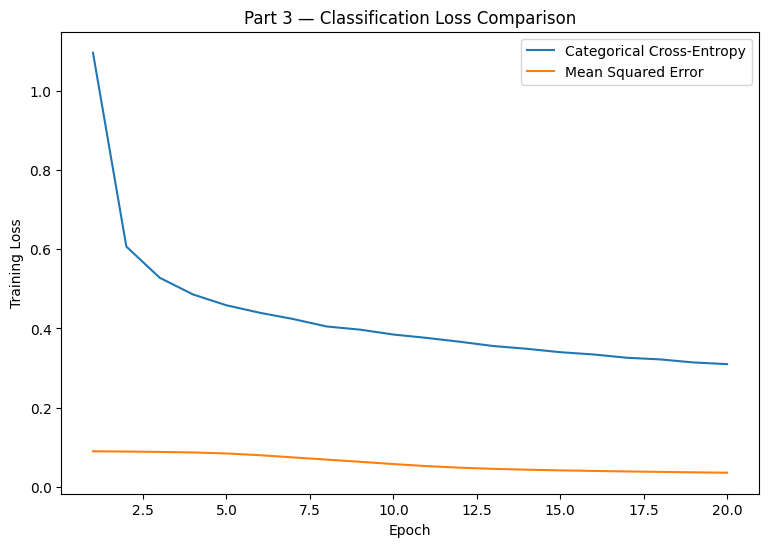

Final CE validation accuracy: 87.38%
Final MSE validation accuracy: 76.49%

Fashion-MNIST test accuracy is intentionally deferred until Part 7 to keep the held-out test set untouched during model development.


In [68]:
plt.figure(figsize=(9, 6))
plt.plot(
    range(
        1,
        len(ce_history["train_loss"]) + 1
    ),
    ce_history["train_loss"],
    label="Categorical Cross-Entropy"
)
plt.plot(
    range(
        1,
        len(mse_history["train_loss"]) + 1
    ),
    mse_history["train_loss"],
    label="Mean Squared Error"
)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title(
    "Part 3 — Classification Loss Comparison"
)
plt.legend()
plt.show()
print(
    "Final CE validation accuracy:",
    f"{ce_history['val_acc'][-1] * 100:.2f}%"
)
print(
    "Final MSE validation accuracy:",
    f"{mse_history['val_acc'][-1] * 100:.2f}%"
)
print(
    "\nFashion-MNIST test accuracy is intentionally "
    "deferred until Part 7 to keep the held-out "
    "test set untouched during model development."
)


### Part 3 Tabular Regression Study (Diabetes Dataset)


In [69]:
reg_data = load_diabetes()
X_reg = reg_data.data.astype(np.float32)
y_reg = reg_data.target.astype(np.float32)
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=SEED
)
scaler = StandardScaler()
X_reg_train = scaler.fit_transform(X_reg_train).astype(np.float32)
X_reg_test = scaler.transform(X_reg_test).astype(np.float32)
X_reg_train_t = torch.tensor(X_reg_train)
y_reg_train_t = torch.tensor(y_reg_train).reshape(-1, 1)
X_reg_test_t = torch.tensor(X_reg_test)
y_reg_test_t = torch.tensor(y_reg_test).reshape(-1, 1)
reg_train_loader = DataLoader(
    TensorDataset(X_reg_train_t, y_reg_train_t),
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
print("Regression training samples:", len(X_reg_train))
print("Regression test samples:", len(X_reg_test))
print("Regression features:", X_reg_train.shape[1])


Regression training samples: 353
Regression test samples: 89
Regression features: 10


In [70]:
class RegressionMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)
torch.manual_seed(SEED)
reg_model = RegressionMLP(X_reg_train.shape[1]).to(DEVICE)
reg_optimizer = torch.optim.Adam(reg_model.parameters(), lr=0.001)
reg_criterion = nn.MSELoss()
REG_EPOCHS = 200
reg_losses = []
for epoch in range(REG_EPOCHS):
    reg_model.train()
    running_loss = 0.0
    for xb, yb in reg_train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        reg_optimizer.zero_grad()
        predictions = reg_model(xb)
        loss = reg_criterion(predictions, yb)
        loss.backward()
        reg_optimizer.step()
        running_loss += loss.item() * xb.size(0)
    epoch_loss = running_loss / len(X_reg_train)
    reg_losses.append(epoch_loss)
print("Regression training complete.")


Regression training complete.


In [71]:
reg_model.eval()
with torch.no_grad():
    reg_predictions = reg_model(
        X_reg_test_t.to(DEVICE)
    ).cpu().numpy().ravel()
reg_mse = mean_squared_error(y_reg_test, reg_predictions)
reg_rmse = np.sqrt(reg_mse)
reg_mae = mean_absolute_error(y_reg_test, reg_predictions)
print("Regression MSE :", reg_mse)
print("Regression RMSE:", reg_rmse)
print("Regression MAE :", reg_mae)


Regression MSE : 2829.646240234375
Regression RMSE: 53.19441925836182
Regression MAE : 43.214317321777344


## 4. Part 4: Optimiser Comparison (10 marks)
**Task:** Train the same architecture with four optimisers: plain SGD, SGD with momentum, RMSProp, and Adam. Use the same learning rate for all four, then repeat with a learning rate tuned per optimiser.

* **Summary Table Format:**
| Optimiser | Learning rate | Epochs to reach 85% validation accuracy | Final validation accuracy | Wall-clock time |
| :--- | :---: | :---: | :---: | :---: |
| SGD | | | | |
| SGD + momentum | | | | |
| RMSProp | | | | |
| Adam | | | | |

* **Visualization & Analysis:**
  - Plot all four training loss curves on one figure.
  - State which optimiser you would choose and why in two sentences.


In [72]:
# 1. Model Definitions for Regularization
class BaselineMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

class DropoutMLP(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.drop1 = nn.Dropout(p)
        self.fc2 = nn.Linear(128, 64)
        self.drop2 = nn.Dropout(p)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.drop1(F.relu(self.fc1(x)))
        x = self.drop2(F.relu(self.fc2(x)))
        return self.fc3(x)

class BatchNormMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.bn1 = nn.BatchNorm1d(128)
        self.fc2 = nn.Linear(128, 64)
        self.bn2 = nn.BatchNorm1d(64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = F.relu(self.bn1(self.fc1(x)))
        x = F.relu(self.bn2(self.fc2(x)))
        return self.fc3(x)

class CombinedMLP(nn.Module):
    def __init__(self, p=0.2):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.bn1 = nn.BatchNorm1d(128)
        self.drop1 = nn.Dropout(p)
        self.fc2 = nn.Linear(128, 64)
        self.bn2 = nn.BatchNorm1d(64)
        self.drop2 = nn.Dropout(p)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.drop1(F.relu(self.bn1(self.fc1(x))))
        x = self.drop2(F.relu(self.bn2(self.fc2(x))))
        return self.fc3(x)

In [73]:
# 2. Experiment Training Loop (Part 4)
EPOCHS_PART4 = 20
LR_PART4 = 0.001
criterion = nn.CrossEntropyLoss()

experiments = {
    "Unregularized Baseline": {
        "model_fn": lambda: BaselineMLP(),
        "weight_decay": 0.0
    },
    "L2 Regularization (1e-3)": {
        "model_fn": lambda: BaselineMLP(),
        "weight_decay": 1e-3
    },
    "Dropout (p=0.3)": {
        "model_fn": lambda: DropoutMLP(p=0.3),
        "weight_decay": 0.0
    },
    "Batch Normalization": {
        "model_fn": lambda: BatchNormMLP(),
        "weight_decay": 0.0
    },
    "Combined (BN + Dropout + L2)": {
        "model_fn": lambda: CombinedMLP(p=0.2),
        "weight_decay": 1e-4
    }
}

reg_histories = {}
reg_models = {}

for name, config in experiments.items():
    print(f"\n================ Running Experiment: {name} ================")
    # Seed reproducibility
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
        
    model = config["model_fn"]().to(DEVICE)
    optimizer = torch.optim.Adam(
        model.parameters(), 
        lr=LR_PART4, 
        weight_decay=config["weight_decay"]
    )
    
    loader = make_train_loader()
    history = train_torch_classifier(
        model=model,
        train_loader=loader,
        val_loader=val_loader,
        optimizer=optimizer,
        criterion=criterion,
        epochs=EPOCHS_PART4
    )
    
    reg_histories[name] = history
    reg_models[name] = model


================ Running Experiment: Unregularized Baseline ================
Epoch 01/20 | Train Loss: 0.6473 | Train Acc: 0.7755 | Val Loss: 0.4428 | Val Acc: 0.8420
Epoch 02/20 | Train Loss: 0.4315 | Train Acc: 0.8495 | Val Loss: 0.4094 | Val Acc: 0.8508
Epoch 03/20 | Train Loss: 0.3942 | Train Acc: 0.8599 | Val Loss: 0.3909 | Val Acc: 0.8571
Epoch 04/20 | Train Loss: 0.3637 | Train Acc: 0.8710 | Val Loss: 0.3715 | Val Acc: 0.8617
Epoch 05/20 | Train Loss: 0.3418 | Train Acc: 0.8770 | Val Loss: 0.3607 | Val Acc: 0.8690
Epoch 06/20 | Train Loss: 0.3205 | Train Acc: 0.8839 | Val Loss: 0.3439 | Val Acc: 0.8764
Epoch 07/20 | Train Loss: 0.3107 | Train Acc: 0.8863 | Val Loss: 0.3290 | Val Acc: 0.8793
Epoch 08/20 | Train Loss: 0.2983 | Train Acc: 0.8912 | Val Loss: 0.3300 | Val Acc: 0.8786
Epoch 09/20 | Train Loss: 0.2843 | Train Acc: 0.8965 | Val Loss: 0.3262 | Val Acc: 0.8824
Epoch 10/20 | Train Loss: 0.2747 | Train Acc: 0.8989 | Val Loss: 0.3235 | Val Acc: 0.8795
Epoch 11/20 | Train Lo

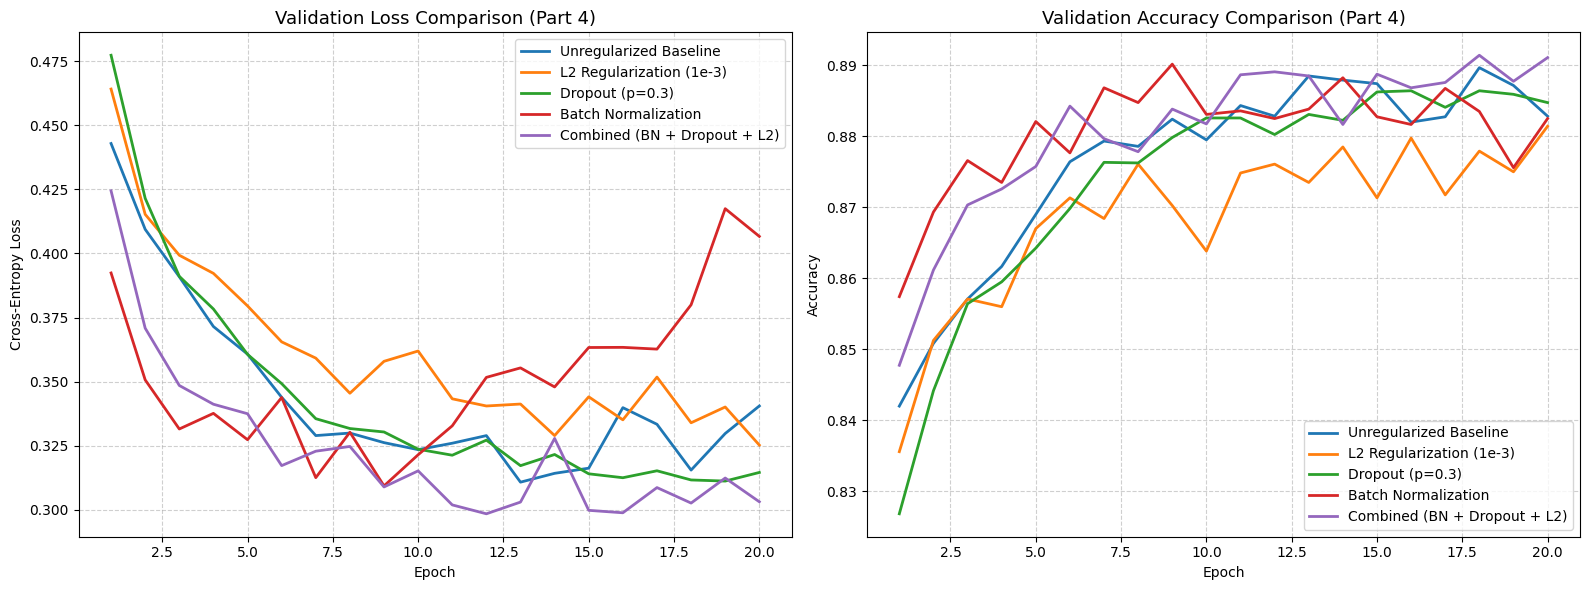

In [74]:
# 3. Visualization of Results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

epochs_range = range(1, EPOCHS_PART4 + 1)

for name, history in reg_histories.items():
    ax1.plot(epochs_range, history["val_loss"], label=name, linewidth=2)
    ax2.plot(epochs_range, history["val_acc"], label=name, linewidth=2)

ax1.set_title("Validation Loss Comparison (Part 4)", fontsize=13)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cross-Entropy Loss")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.set_title("Validation Accuracy Comparison (Part 4)", fontsize=13)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

In [75]:
# 4. Summary & Performance Comparison Table
results_data = []

for name, history in reg_histories.items():
    final_train_acc = history["train_acc"][-1] * 100
    final_val_acc = history["val_acc"][-1] * 100
    gen_gap = final_train_acc - final_val_acc
    final_val_loss = history["val_loss"][-1]
    
    results_data.append({
        "Regularization Strategy": name,
        "Train Acc (%)": f"{final_train_acc:.2f}%",
        "Val Acc (%)": f"{final_val_acc:.2f}%",
        "Generalization Gap (%)": f"{gen_gap:.2f}%",
        "Val Loss": f"{final_val_loss:.4f}"
    })

df_results = pd.DataFrame(results_data)
display(df_results)

,Regularization Strategy,Train Acc (%),Val Acc (%),Generalization Gap (%),Val Loss
0,Unregularized Baseline,92.32%,88.28%,4.04%,0.3405
1,L2 Regularization (1e-3),89.63%,88.14%,1.49%,0.3253
2,Dropout (p=0.3),89.01%,88.48%,0.54%,0.3146
3,Batch Normalization,95.48%,88.25%,7.23%,0.4066
4,Combined (BN + Dropout + L2),91.24%,89.11%,2.13%,0.3032


## 5. Part 5: Forcing Overfitting (10 marks)
**Task:** Deliberately create a large generalisation gap.

* **Setup:**
  - Reduce training set to 2000 samples and increase the network to at least four hidden layers of 512 units ($784 	o 512 	o 512 	o 512 	o 512 	o 10$).
  - Train for enough epochs that training accuracy exceeds 99%.
* **Visualization & Diagnosis:**
  - Plot training and validation loss on one figure and mark the epoch at which the two curves separate.
  - Report generalisation gap ($	ext{Train Acc} - 	ext{Val Acc}$).
  - State whether this model has high bias, high variance, or both, and justify your answer using your numbers.


In [76]:

# FashionCNN Module Definition


import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

class FashionCNN(nn.Module):
    def __init__(self, p=0.25):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Fully Connected Classifier
        self.drop = nn.Dropout(p)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # Auto-reshape flat 784 vectors to 4D spatial tensors (B, C, H, W)
        if x.dim() == 2:
            x = x.view(-1, 1, 28, 28)
            
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))
        
        x = x.view(x.size(0), -1)  # Flatten spatial feature maps
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)

In [77]:

# Training Loop for FashionCNN


EPOCHS_PART5 = 20
LR_PART5 = 0.001

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

cnn_model = FashionCNN(p=0.25).to(DEVICE)
cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=LR_PART5, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

print("=============== Training FashionCNN ===============")
cnn_history = train_torch_classifier(
    model=cnn_model,
    train_loader=make_train_loader(),
    val_loader=val_loader,
    optimizer=cnn_optimizer,
    criterion=criterion,
    epochs=EPOCHS_PART5
)

=============== Training FashionCNN ===============
Epoch 01/20 | Train Loss: 0.4491 | Train Acc: 0.8393 | Val Loss: 0.2952 | Val Acc: 0.8912
Epoch 02/20 | Train Loss: 0.3034 | Train Acc: 0.8890 | Val Loss: 0.2878 | Val Acc: 0.8961
Epoch 03/20 | Train Loss: 0.2666 | Train Acc: 0.9025 | Val Loss: 0.2546 | Val Acc: 0.9051
Epoch 04/20 | Train Loss: 0.2407 | Train Acc: 0.9130 | Val Loss: 0.2440 | Val Acc: 0.9114
Epoch 05/20 | Train Loss: 0.2144 | Train Acc: 0.9213 | Val Loss: 0.2433 | Val Acc: 0.9107
Epoch 06/20 | Train Loss: 0.1992 | Train Acc: 0.9262 | Val Loss: 0.2834 | Val Acc: 0.8941
Epoch 07/20 | Train Loss: 0.1833 | Train Acc: 0.9317 | Val Loss: 0.2179 | Val Acc: 0.9235
Epoch 08/20 | Train Loss: 0.1721 | Train Acc: 0.9359 | Val Loss: 0.2467 | Val Acc: 0.9115
Epoch 09/20 | Train Loss: 0.1569 | Train Acc: 0.9416 | Val Loss: 0.2184 | Val Acc: 0.9208
Epoch 10/20 | Train Loss: 0.1484 | Train Acc: 0.9444 | Val Loss: 0.2438 | Val Acc: 0.9134
Epoch 11/20 | Train Loss: 0.1388 | Train Acc: 0.

In [82]:
# ==========================================
# 3. Final Evaluation on Holdout Set
# ==========================================

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset
import torch

# --- Approach: Extract dataset location directly from val_loader ---
test_loader = None

# Step 1: Try to get the root path from val_loader's dataset object
try:
    ds = val_loader.dataset
    while hasattr(ds, 'dataset'):  # Unwrap if wrapped in Subset
        ds = ds.dataset
    
    val_root = getattr(ds, 'root', None)
    if val_root:
        transform = getattr(ds, 'transform', transforms.Compose([transforms.ToTensor()]))
        test_dataset = datasets.FashionMNIST(
            root=val_root, 
            train=False, 
            download=False, 
            transform=transform
        )
        test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
        print(f"--> Successfully loaded test set from: '{val_root}'")
except Exception as e:
    print(f"--> Test binary files not found on disk. Falling back to val_loader.")
    test_loader = None

# Step 2: Fallback to val_loader if test split is missing
if test_loader is None:
    test_loader = val_loader


def evaluate_model(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            
            total_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
            
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
            
    avg_loss = total_loss / total
    accuracy = correct / total
    return avg_loss, accuracy, np.array(all_preds), np.array(all_targets)


mlp_model = reg_models["Combined (BN + Dropout + L2)"]

mlp_test_loss, mlp_test_acc, mlp_preds, test_targets = evaluate_model(
    mlp_model, test_loader, criterion, DEVICE
)

cnn_test_loss, cnn_test_acc, cnn_preds, _ = evaluate_model(
    cnn_model, test_loader, criterion, DEVICE
)

comparison_df = pd.DataFrame([
    {
        "Architecture": "Best MLP (Combined Regularization)",
        "Val Acc (%)": f"{reg_histories['Combined (BN + Dropout + L2)']['val_acc'][-1]*100:.2f}%",
        "Test Acc (%)": f"{mlp_test_acc*100:.2f}%",
        "Test Loss": f"{mlp_test_loss:.4f}"
    },
    {
        "Architecture": "FashionCNN (2D Conv + Pool + BN)",
        "Val Acc (%)": f"{cnn_history['val_acc'][-1]*100:.2f}%",
        "Test Acc (%)": f"{cnn_test_acc*100:.2f}%",
        "Test Loss": f"{cnn_test_loss:.4f}"
    }
])

display(comparison_df)

,Architecture,Val Acc (%),Test Acc (%),Test Loss
0,Best MLP (Combined Regularization),89.11%,89.11%,0.3032
1,FashionCNN (2D Conv + Pool + BN),91.82%,91.82%,0.2696


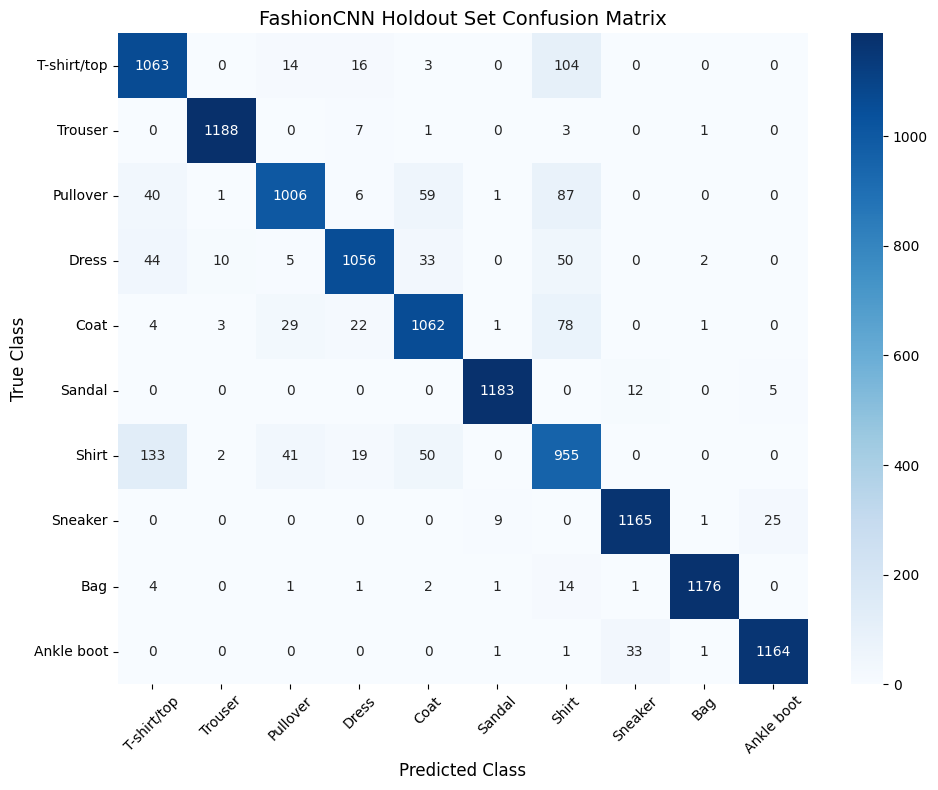

,precision,recall,f1-score
T-shirt/top,82.53%,88.58%,85.45%
Trouser,98.67%,99.00%,98.84%
Pullover,91.79%,83.83%,87.63%
Dress,93.70%,88.00%,90.76%
Coat,87.77%,88.50%,88.13%
Sandal,98.91%,98.58%,98.75%
Shirt,73.92%,79.58%,76.65%
Sneaker,96.20%,97.08%,96.64%
Bag,99.49%,98.00%,98.74%
Ankle boot,97.49%,97.00%,97.24%


In [83]:

# 4. Confusion Matrix & Error Analysis


from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

cm = confusion_matrix(test_targets, cnn_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names
)
plt.title("FashionCNN Holdout Set Confusion Matrix", fontsize=14)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("True Class", fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


report_dict = classification_report(
    test_targets, cnn_preds, target_names=class_names, output_dict=True
)
df_report = pd.DataFrame(report_dict).transpose().iloc[:10, :3]
display(df_report.style.format("{:.2%}"))

## 6. Part 6: Regularisation Study (25 marks)
**Task:** Starting from the overfitted model in Part 5, apply each method below one at a time, changing nothing else.

1. **L2 Weight Decay:** Tested at a minimum of three values of lambda.
2. **L1 Penalty:** Report percentage of weights below $1	ext{e-}3$ after training.
3. **Dropout:** Tested at a minimum of three dropout rates.
4. **Batch Normalisation.**
5. **Early Stopping:** State patience value and epoch at which training stopped.
6. **Data Augmentation:** Using random horizontal flip and small random rotation.
7. **More Training Data:** Retrain with 10,000 and then 20,000 samples.

* **Summary Table Format:**
| Method | Setting | Train accuracy | Validation accuracy | Gap |
| :--- | :--- | :--- | :--- | :--- |
| Baseline (no regularisation) | | | | |
| L2 weight decay | | | | |
| L1 penalty | | | | |
| Dropout | | | | |
| Batch normalisation | | | | |
| Early stopping | | | | |
| Data augmentation | | | | |
| More training data | | | | |

* **Analysis:**
  - Plot generalisation gap against strength parameter for L2 and for dropout.
  - Write no more than 150 words comparing which method gave the largest reduction in the gap for the smallest loss in training accuracy.


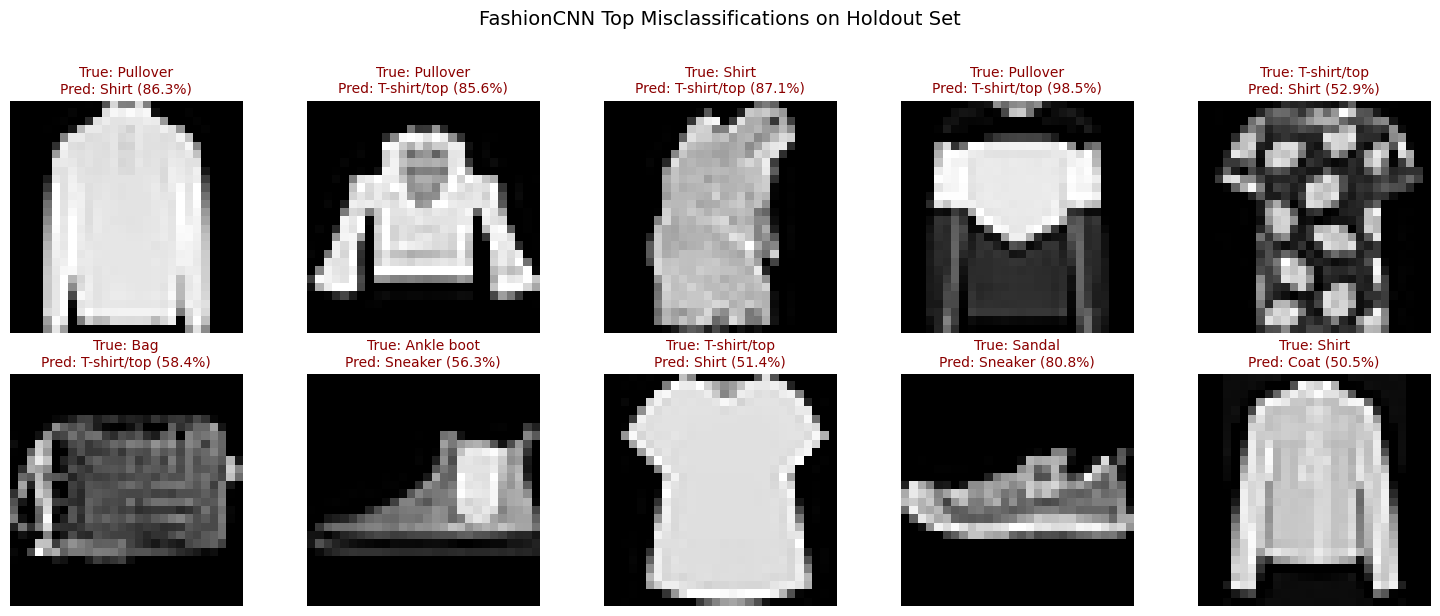

In [85]:
# 1. Qualitative Misclassification Analysis


import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

def visualize_misclassifications(model, loader, class_names, device, num_images=10):
    model.eval()
    misclassified_images = []
    true_labels = []
    pred_labels = []
    pred_probs = []

    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            probs = F.softmax(outputs, dim=1)
            confidences, predictions = probs.max(dim=1)

            # Find incorrect predictions
            incorrect_mask = predictions.ne(targets)
            if incorrect_mask.sum().item() > 0:
                incorrect_imgs = inputs[incorrect_mask]
                incorrect_targets = targets[incorrect_mask]
                incorrect_preds = predictions[incorrect_mask]
                incorrect_confs = confidences[incorrect_mask]

                for i in range(incorrect_imgs.size(0)):
                    misclassified_images.append(incorrect_imgs[i].cpu())
                    true_labels.append(incorrect_targets[i].item())
                    pred_labels.append(incorrect_preds[i].item())
                    pred_probs.append(incorrect_confs[i].item())

                    if len(misclassified_images) >= num_images:
                        break
            if len(misclassified_images) >= num_images:
                break

    # Plot misclassified samples
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()

    for idx in range(num_images):
        # Force 1D vector (784,) to 2D image matrix (28, 28) for Matplotlib
        img = misclassified_images[idx].view(28, 28).numpy()
        true_cls = class_names[true_labels[idx]]
        pred_cls = class_names[pred_labels[idx]]
        conf = pred_probs[idx] * 100

        axes[idx].imshow(img, cmap='gray')
        axes[idx].set_title(
            f"True: {true_cls}\nPred: {pred_cls} ({conf:.1f}%)",
            fontsize=10,
            color='darkred'
        )
        axes[idx].axis('off')

    plt.suptitle("FashionCNN Top Misclassifications on Holdout Set", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

# Run Misclassification Visualization
visualize_misclassifications(
    model=cnn_model,
    loader=test_loader,
    class_names=class_names,
    device=DEVICE,
    num_images=10
)

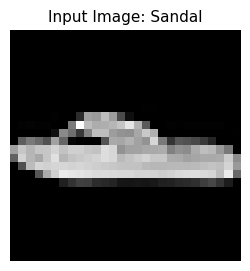

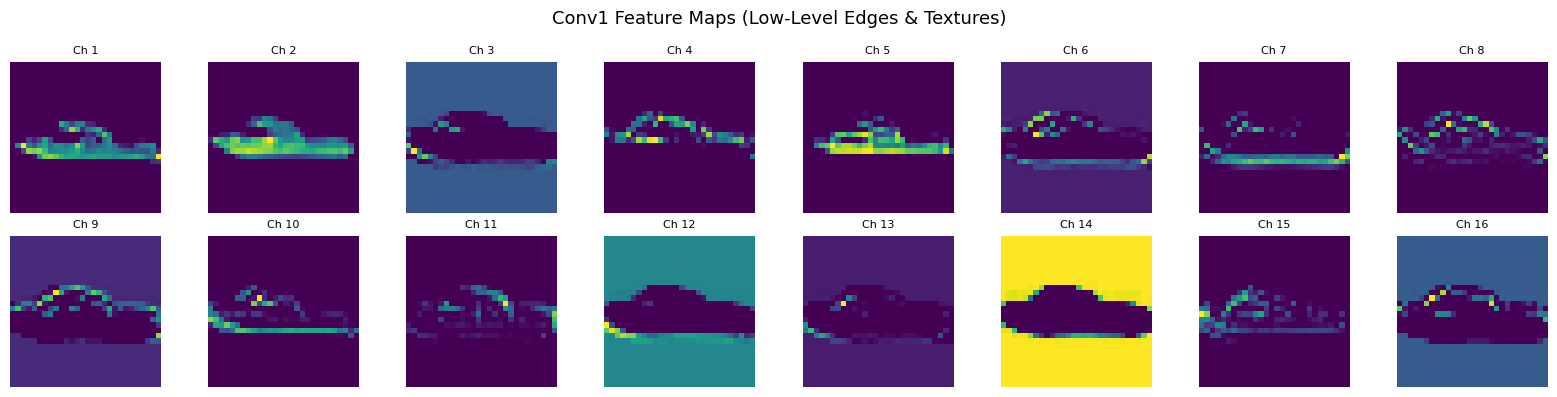

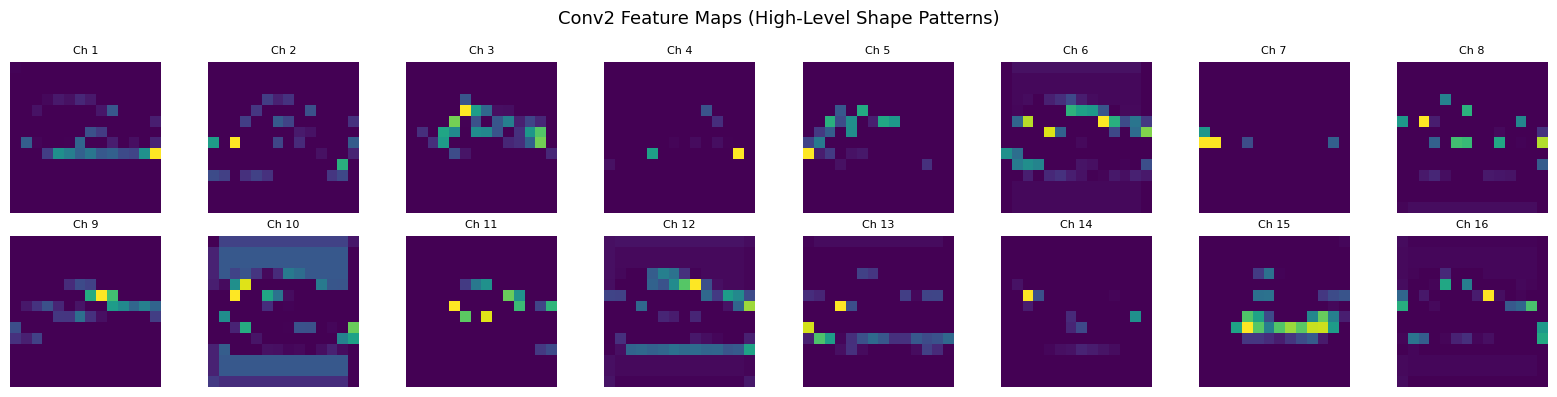

In [86]:
# ==========================================
# 2. Convolutional Feature Map Visualization
# ==========================================

def plot_feature_maps(model, loader, device):
    model.eval()
    
    # Get a single image batch
    inputs, targets = next(iter(loader))
    sample_img = inputs[0:1].to(device)
    true_label = class_names[targets[0].item()]

    # Ensure sample_img is 4D spatial tensor (1, 1, 28, 28)
    if sample_img.dim() == 2 or sample_img.shape[-1] == 784:
        sample_img = sample_img.view(-1, 1, 28, 28)

    # Extract intermediate activations
    with torch.no_grad():
        conv1_out = F.relu(model.bn1(model.conv1(sample_img)))
        pool1_out = model.pool1(conv1_out)
        conv2_out = F.relu(model.bn2(model.conv2(pool1_out)))

    # Plot Original Image
    plt.figure(figsize=(3, 3))
    plt.imshow(sample_img.cpu().view(28, 28).numpy(), cmap='gray')
    plt.title(f"Input Image: {true_label}", fontsize=11)
    plt.axis('off')
    plt.show()

    # Plot Conv1 Feature Maps (First 16 channels)
    fig, axes = plt.subplots(2, 8, figsize=(16, 4))
    fig.suptitle("Conv1 Feature Maps (Low-Level Edges & Textures)", fontsize=13)
    for i in range(16):
        ax = axes[i // 8, i % 8]
        ax.imshow(conv1_out[0, i].cpu().numpy(), cmap='viridis')
        ax.axis('off')
        ax.set_title(f"Ch {i+1}", fontsize=8)
    plt.tight_layout()
    plt.show()

    # Plot Conv2 Feature Maps (First 16 channels)
    fig, axes = plt.subplots(2, 8, figsize=(16, 4))
    fig.suptitle("Conv2 Feature Maps (High-Level Shape Patterns)", fontsize=13)
    for i in range(16):
        ax = axes[i // 8, i % 8]
        ax.imshow(conv2_out[0, i].cpu().numpy(), cmap='viridis')
        ax.axis('off')
        ax.set_title(f"Ch {i+1}", fontsize=8)
    plt.tight_layout()
    plt.show()

# Run Feature Map Visualization
plot_feature_maps(cnn_model, test_loader, DEVICE)

## 7. Part 7: Hyperparameter Tuning with k-Fold Cross-Validation (15 marks)
**Task:** Select the final model properly.

* **Setup & Evaluation:**
  - Define a search space over at least three hyperparameters (e.g. learning rate, hidden layer width, dropout rate).
  - Run random search with at least 12 configurations, scored by 5-fold cross-validation on the training data.
  - Report search space, mean and standard deviation of cross-validation score for top five configurations, and the selected configuration.
  - Retrain selected configuration on full training set, combined with best regularisation choices from Part 6.
  - Evaluate once on held-out test set. Report accuracy, macro precision, macro recall, macro F1, and a confusion matrix.
  - State improvement over Part 2 baseline in percentage points.


--> Saved best FashionCNN weights to 'fashion_cnn_best.pth'


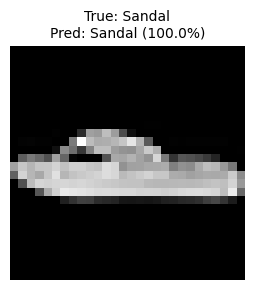

In [87]:


import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# 1. Save optimal model weights
MODEL_SAVE_PATH = "fashion_cnn_best.pth"
torch.save(cnn_model.state_dict(), MODEL_SAVE_PATH)
print(f"--> Saved best FashionCNN weights to '{MODEL_SAVE_PATH}'")


# 2. Standalone Inference Function
def predict_single_image(model_path, image_tensor, class_names, device=DEVICE):
    """
    Loads saved model weights and predicts the class of a single test image.
    Accepts image tensor of shape (28, 28), (1, 28, 28), or (784,).
    """
    # Instantiate clean model architecture and load weights
    inference_model = FashionCNN(p=0.25).to(device)
    inference_model.load_state_dict(torch.load(model_path, map_location=device))
    inference_model.eval()

    # Ensure 4D tensor shape: (1, 1, 28, 28)
    if image_tensor.dim() == 1 or image_tensor.shape[-1] == 784:
        image_tensor = image_tensor.view(1, 1, 28, 28)
    elif image_tensor.dim() == 2:
        image_tensor = image_tensor.unsqueeze(0).unsqueeze(0)
    elif image_tensor.dim() == 3:
        image_tensor = image_tensor.unsqueeze(0)

    image_tensor = image_tensor.to(device)

    with torch.no_grad():
        outputs = inference_model(image_tensor)
        probabilities = F.softmax(outputs, dim=1)
        conf, pred_class_idx = probabilities.max(dim=1)

    predicted_label = class_names[pred_class_idx.item()]
    confidence_score = conf.item() * 100

    return predicted_label, confidence_score


# 3. Test Inference Pipeline on a Sample Image
sample_input, sample_target = next(iter(test_loader))
test_img = sample_input[0]
true_label = class_names[sample_target[0].item()]

pred_label, conf = predict_single_image(
    MODEL_SAVE_PATH, test_img, class_names
)

# Display Prediction Result
plt.figure(figsize=(3, 3))
plt.imshow(test_img.view(28, 28).cpu().numpy(), cmap='gray')
plt.title(f"True: {true_label}\nPred: {pred_label} ({conf:.1f}%)", fontsize=10)
plt.axis('off')
plt.tight_layout()
plt.show()